# 01 · Leaf Surgery 101

**Tree Surgery** asks whether an LLM can improve a trained LightGBM model by editing its leaf values directly, without retraining.

Before any LLM shows up, this notebook covers the mechanics:

1. Train a base model on a semi-synthetic delivery-time dataset where we know the true function.
2. Open a leaf: every leaf is a readable rule plus one number.
3. Edit one leaf and confirm that exactly the samples in that leaf move, by exactly δ.
4. See why the problem is **linear**: predictions = (one-hot leaf matrix) × (leaf values).
5. Roll an edit back.
6. Preview what the LLM will be shown.

Runs in about 10 seconds on a laptop or Colab. No API keys needed.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/debabrot/research-llm-model-optimization/blob/main/notebooks/01_leaf_surgery_101.ipynb)

In [1]:
# Setup: works locally (run from notebooks/) and in Colab.
import sys, os
if "google.colab" in sys.modules:
    !pip -q install lightgbm pyyaml
    REPO_URL = "https://github.com/debabrot/research-llm-model-optimization"
    if not os.path.exists("research-llm-model-optimization"):
        !git clone -q {REPO_URL}
    sys.path.insert(0, "research-llm-model-optimization")
else:
    sys.path.insert(0, os.path.abspath(".."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tree_surgery as ts
from tree_surgery.design_matrix import leaf_assignments
from tree_surgery.evaluation import rmse

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6})
pd.set_option("display.max_colwidth", 120)

## 1 · Data and base model

D1 is a generated food-delivery dataset with meaningful feature names. The target is built from a fixed formula: main effects, a `rain × traffic` interaction, a rush-hour `× distance` interaction, a threshold on order size, and heteroscedastic noise (SNR ≈ 3). Because we keep the noise-free truth `f_true`, we can tell whether an edit moves the model **toward the truth** or only fits noise.

Splits are 50 / 15 / 15 / 20: **train** fits the model, **calibration** is the only labelled data an editor may use, **validation** selects candidates, and **test** is untouched until the end.

In [2]:
data = ts.load_dataset("delivery", seed=0)
print({k: len(s.y) for k, s in data.splits.items()})
data["train"].X.head()

{'train': 10000, 'cal': 3000, 'val': 3000, 'test': 4000}


,distance_km,hour,rain_mm,traffic_index,driver_experience_yrs,order_size,prep_time_min,is_weekend
0,8.36,11,0.0,3.70,0.3,4,14.8,0
1,6.16,4,1.2,4.51,0.6,2,14.1,0
2,5.01,1,1.9,3.72,0.4,2,11.3,0
3,1.24,19,0.0,4.23,8.0,3,20.0,1
4,3.34,18,0.0,6.74,0.5,6,10.3,0


In [3]:
booster, info = ts.fit_base_model(data)   # LightGBM, num_leaves=15, lr=0.05, early stopping on val
print(f"trees: {info.num_trees}   leaves: {info.num_leaves_total}")
pd.DataFrame(info.metrics).T.round(3)

trees: 267   leaves: 4005


,rmse,mae,r2,rmse_vs_truth
train,3.693,2.736,0.919,1.326
cal,4.251,2.993,0.893,1.668
val,4.450,3.158,0.876,1.411
test,4.239,3.044,0.895,1.469


The model's test RMSE (~4.2 min) is close to the irreducible noise. Its error against the noise-free truth (`rmse_vs_truth`, ~1.5 min) is the part an edit could actually fix.

Note the leaf count: about **4,000 leaves**. Every one of them is a single number we are allowed to change.

## 2 · Open a leaf

`leaf_table` lists every leaf with its decision rule, its current value, and residual statistics on the **calibration** split. Residual = y − ŷ, so a positive `mean_resid` means the model under-predicts in that leaf.

In [4]:
patcher = ts.ModelPatcher(booster)          # frozen snapshot of the base model
cal = data["cal"]
table = ts.leaf_table(booster, cal.X, cal.y, patcher.index)
rules = ts.extract_rules(booster)
table.sort_values("n_cal", ascending=False).head(8)

,tree_id,leaf_id,depth,rule,value,n_train,n_cal,mean_resid,std_resid
3885,259,0,2,order_size <= 8.5 AND traffic_index <= 8.29,-0.000666,9443,2832,-0.035453,4.264107
3720,248,0,3,prep_time_min <= 22.9 AND distance_km <= 17.4,-0.000388,9382,2788,-0.044974,4.012709
3841,256,1,1,order_size > 1.5,0.000664,9198,2743,0.006960,4.237824
3736,249,1,1,order_size > 1.5,0.000703,9198,2743,0.006960,4.237824
3991,266,1,1,order_size > 1.5,0.000632,9198,2743,0.006960,4.237824
3375,225,0,3,driver_experience_yrs <= 9.35 AND order_size <= 6.5,-0.000454,9148,2733,0.002544,4.223802
2893,192,13,8,rain_mm <= 30 AND 0.935 < distance_km <= 21 AND order_size <= 7.5 AND 0 < driver_experience_yrs <= 14.3 AND traffic_...,0.000201,8909,2677,-0.011796,4.214832
3299,219,14,2,order_size > 1.5 AND distance_km > 0.595,0.001411,8966,2675,0.021536,4.282133


Tree 0 is special. LightGBM folds the global mean of the target (~36 min) into the first tree's leaves, so their values are large. Every later tree holds small corrections.

A rule is not just a label; it's an exact description. The check below confirms that the rows matched by the rule are precisely the rows LightGBM routes to that leaf.

In [5]:
t, l = 2, 10
rule = rules[(t, l)]
print(f"T{t}/L{l}:", rule.text())
matches_rule = rule.mask(cal.X)
lands_in_leaf = leaf_assignments(booster, cal.X)[:, t] == l
print("rule selects", matches_rule.sum(), "rows; identical to LightGBM routing:", np.array_equal(matches_rule, lands_in_leaf))

T2/L10: 8.85 < distance_km <= 11.9 AND traffic_index > 5.25
rule selects 97 rows; identical to LightGBM routing: True


## 3 · Surgery on one leaf

Add δ = +5 minutes to that one leaf. Every sample that lands in it should move up by exactly 5, and every other sample should not move at all.

In [6]:
delta = 5.0
cand = patcher.candidate()                 # independent copy; the base is never touched
cand.apply({(t, l): delta})

X = data["test"].X
change = cand.predict(X) - booster.predict(X)
in_leaf = leaf_assignments(booster, X)[:, t] == l
print(f"in leaf : n={in_leaf.sum():5d}  change min/max = {change[in_leaf].min():.12f} / {change[in_leaf].max():.12f}")
print(f"elsewhere: n={(~in_leaf).sum():5d}  change min/max = {change[~in_leaf].min():.1f} / {change[~in_leaf].max():.1f}")

in leaf : n=  119  change min/max = 5.000000000000 / 5.000000000000
elsewhere: n= 3881  change min/max = 0.0 / 0.0


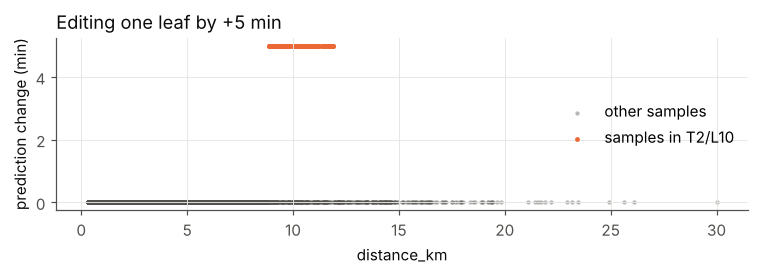

In [7]:
fig, ax = plt.subplots(figsize=(7, 2.6))
order = np.argsort(X["distance_km"].to_numpy())
xs = X["distance_km"].to_numpy()[order]
ax.scatter(xs[~in_leaf[order]], change[order][~in_leaf[order]], s=8, color=MUTED, alpha=0.4, label="other samples", linewidths=0)
ax.scatter(xs[in_leaf[order]], change[order][in_leaf[order]], s=10, color=ORANGE, label=f"samples in T{t}/L{l}", linewidths=0)
ax.set_xlabel("distance_km"); ax.set_ylabel("prediction change (min)")
ax.set_title(f"Editing one leaf by +{delta:g} min", loc="left", color=INK)
ax.legend(frameon=False, loc="center right")
plt.tight_layout(); plt.show()

## 4 · Why the problem is linear

With the tree structure frozen, a prediction is just the sum of one leaf value per tree:

$$\hat y(x) = \sum_t v_{t,\,\text{leaf}_t(x)} = X_{\text{leaf}}(x)\, v$$

`X_leaf` is a sparse 0/1 matrix (n × L) with exactly one 1 per tree in each row. An edit is a delta vector **d**, and the edited model predicts **ŷ + X·d**.

This is what makes the experiment fair. Choosing values for a fixed set of leaves is ridge regression with a closed-form answer. Choosing *which* leaves is sparse regression. The LLM has to beat that.

In [8]:
A = ts.leaf_design_matrix(booster, X, patcher.index)
print("shape:", A.shape, "  nonzeros per row:", np.unique(A.getnnz(axis=1)))
print("max |X·v − predict|:", np.abs(A @ patcher.base_values - booster.predict(X)).max())

rng = np.random.default_rng(0)
keys = [patcher.index.key(int(c)) for c in rng.choice(patcher.index.num_leaves, 10, replace=False)]
multi = patcher.candidate().apply({k: float(rng.normal(0, 2)) for k in keys})
print("max |(ŷ + X·d) − edited predict|:", np.abs(booster.predict(X) + A @ multi.delta_vector() - multi.predict(X)).max())

shape: (4000, 4005)   nonzeros per row: [267]
max |X·v − predict|: 0.0
max |(ŷ + X·d) − edited predict|: 7.105427357601002e-14


### A taste of the competition (preview, not an experiment arm)

A one-line heuristic: pick the 10 leaves with the largest total calibration residual, then fit their deltas by ridge regression on calibration. Phase 2 builds the real non-LLM arms (`sparse_opt`, `random_opt`, `refit`, `retrain`) with proper candidate selection.

In [9]:
from scipy.sparse.linalg import lsqr

cal_A = ts.leaf_design_matrix(booster, cal.X, patcher.index)
cal_resid = cal.y - booster.predict(cal.X)
score = (table["n_cal"] * table["mean_resid"]).abs().fillna(0).to_numpy()
cols = np.argsort(score)[::-1][:10]
lam = 10.0
d_sub = lsqr(cal_A[:, cols], cal_resid, damp=np.sqrt(lam))[0]   # ridge on the 10 chosen leaves

preview = patcher.candidate().apply({patcher.index.key(int(c)): float(v) for c, v in zip(cols, d_sub)})
rows = []
for split in ("cal", "val"):
    s = data[split]
    rows.append({"split": split, "base": rmse(s.y, booster.predict(s.X)), "edited": rmse(s.y, preview.predict(s.X)),
                 "base vs truth": rmse(s.f_true, booster.predict(s.X)), "edited vs truth": rmse(s.f_true, preview.predict(s.X))})
pd.DataFrame(rows).set_index("split").round(4)

,base,edited,base vs truth,edited vs truth
split,,,,
cal,4.2508,4.2351,1.6675,1.6722
val,4.4499,4.4560,1.4113,1.4182


Calibration error drops a little, but on this seed validation error and error against the truth get slightly *worse*. The naive edit fits calibration noise. This is why every arm is selected on validation and reported on test, and why a well-tuned base model leaves little room. (Test is not shown here on purpose.)

## 5 · Rollback

Every edit is logged with the exact old value, so undoing it is bit-for-bit exact.

In [10]:
print("edits logged:", len(preview.edit_log)); print(preview.edit_log[0])
preview.rollback()
print("predictions identical to base after rollback:", np.array_equal(preview.predict(X), booster.predict(X)))

edits logged: 10
LeafEdit(tree_id=129, leaf_id=7, delta=-1.0304831611277774, old_value=-0.00787896796659857, new_value=-1.0383621290943759)
predictions identical to base after rollback: True


## 6 · What the LLM will see

Each leaf is rendered as one line (PLAN §5). In the `anon` ablation the same model is shown with features renamed to `f0…fN` in a shuffled order. If the LLM does equally well without real names, it isn't using what the features mean.

In [11]:
top = table.sort_values("n_cal", ascending=False).iloc[20:25]
print("named:"); print("\n".join(ts.render_leaf_table(top)))
amap = ts.anon_mapping(data.feature_names, data.seed)
print("\nanon:"); print("\n".join(ts.render_leaf_table(top, rules=rules, name_map=amap)))

all_lines = ts.render_leaf_table(table)
print(f"\nfull table: {len(all_lines)} lines, ~{len(chr(10).join(all_lines)) / 4 / 1000:.0f}K tokens (chars/4 estimate)")

named:
T175/L8 | rule: rain_mm <= 30 AND 1.1 < distance_km <= 17.4 AND order_size <= 7.5 AND traffic_index > 0.535 AND prep_time_min <= 20.7 | n_cal=2285 | value=-0.000145 | mean_resid=-0.0573 | std_resid=4.19
T221/L0 | rule: order_size <= 4.5 | n_cal=2279 | value=-0.00164 | mean_resid=-0.0714 | std_resid=4.18
T208/L0 | rule: order_size <= 4.5 | n_cal=2279 | value=-0.00183 | mean_resid=-0.0714 | std_resid=4.18
T178/L0 | rule: order_size <= 4.5 | n_cal=2279 | value=-0.00249 | mean_resid=-0.0714 | std_resid=4.18
T214/L11 | rule: order_size <= 8.5 AND driver_experience_yrs > 0 AND hour > 10.5 | n_cal=2274 | value=-0.00177 | mean_resid=-0.0903 | std_resid=4.21

anon:
T175/L8 | rule: f4 <= 30 AND 1.1 < f7 <= 17.4 AND f5 <= 7.5 AND f0 > 0.535 AND f1 <= 20.7 | n_cal=2285 | value=-0.000145 | mean_resid=-0.0573 | std_resid=4.19
T221/L0 | rule: f5 <= 4.5 | n_cal=2279 | value=-0.00164 | mean_resid=-0.0714 | std_resid=4.18
T208/L0 | rule: f5 <= 4.5 | n_cal=2279 | value=-0.00183 | mean_resid=-0.071

That last number matters. The full leaf table is too big to show the LLM on every call. How to handle it is an open design decision before Phase 2. See PLAN.md's changelog.

**Next:** `02_the_experiment.ipynb` runs the arms (Phase 2+).